In [1]:
!pip install git+https://github.com/huggingface/transformers

  Cloning https://github.com/huggingface/transformers to /tmp/pip-req-build-vg10dx80
  Running command git clone --filter=blob:none --quiet https://github.com/huggingface/transformers /tmp/pip-req-build-vg10dx80
  Resolved https://github.com/huggingface/transformers to commit 7a50c7864bdfcfcefbd6794066f558386c75c0ed
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for transformers: filename=transformers-5.21.0.dev0-py3-none-any.whl size=14256998 sha256=4dbf0ea9517c05b69853175f24d9af60324b4b7d7d417d2e6e2fd96e596f5a0d
  Stored in directory: /tmp/pip-ephem-wheel-cache-sem5s3f4/wheels/2b/de/48/1c5b158806820c3979e1dc7a341b68dac1231f00b1a2c9442f
Successfully built transformers
  Attempting uninstall: transformers
    Found existing installation: transformers 5.20.1
    Uninstalling transformers-5.20.1:
      Successfully uninstalled transformers-5.20.1


In [2]:
!pip install jupyterlab ipywidgets bertviz xformers evaluate matplotlib

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 17.2/17.2 MB 99.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 157.5/157.5 kB 19.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.3/3.3 MB 114.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.1/84.1 kB 9.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 947.5/947.5 kB 63.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 77.5/77.5 kB 10.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 60.2/60.2 kB 6.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 140.0/140.0 kB 16.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.1/16.1 MB 97.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 126.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 90.3/90.3 kB 11.9 MB/s eta 0:00:00


# Tokenizers

In [3]:
from transformers import BertModel, BertTokenizer

modelName = "bert-base-uncased"

tokenizer = BertTokenizer.from_pretrained(modelName)
model = BertModel.from_pretrained(modelName)

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  440MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.bias                       | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


In [4]:
tokenized = tokenizer("I read a good novel.")
print(tokenized)

{'input_ids': [101, 1045, 3191, 1037, 2204, 3117, 1012, 102], 'token_type_ids': [0, 0, 0, 0, 0, 0, 0, 0], 'attention_mask': [1, 1, 1, 1, 1, 1, 1, 1]}


In [5]:
tokens = tokenizer.convert_ids_to_tokens(tokenized["input_ids"])
print(tokens)

['[CLS]', 'i', 'read', 'a', 'good', 'novel', '.', '[SEP]']


# Positional Encoding

In [7]:
import numpy as np
import matplotlib.pyplot as plt

def encodePositions(num_tokens, depth, n=10000):
    positionalMatrix = np.zeros((num_tokens, depth))
    for row in range(num_tokens):
        for col in np.arange(int(depth/2)):
            denominator = np.power(n, 2*col/depth)
            positionalMatrix[row, 2*col] = np.sin(row/denominator)
            positionalMatrix[row, 2*col+1] = np.cos(row/denominator)
    return positionalMatrix

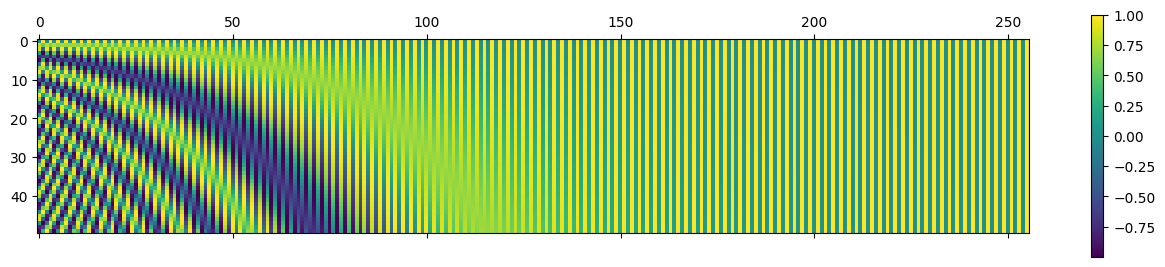

In [8]:
positionalMatrix = encodePositions(50, 256)
fig = plt.matshow(positionalMatrix)
plt.gcf().colorbar(fig)

# Self-Attention

In [9]:
from bertviz.transformers_neuron_view import BertModel, BertTokenizer
from bertviz.neuron_view import show

tokenizer_viz = BertTokenizer.from_pretrained(modelName)
model_viz = BertModel.from_pretrained(modelName)

100%|██████████| 440473133/440473133 [00:11<00:00, 38334349.13B/s]


In [13]:
model_viz

BertModel(
  (embeddings): BertEmbeddings(
    (word_embeddings): Embedding(30522, 768, padding_idx=0)
    (position_embeddings): Embedding(512, 768)
    (token_type_embeddings): Embedding(2, 768)
    (LayerNorm): BertLayerNorm()
    (dropout): Dropout(p=0.1, inplace=False)
  )
  (encoder): BertEncoder(
    (layer): ModuleList(
      (0-11): 12 x BertLayer(
        (attention): BertAttention(
          (self): BertSelfAttention(
            (query): Linear(in_features=768, out_features=768, bias=True)
            (key): Linear(in_features=768, out_features=768, bias=True)
            (value): Linear(in_features=768, out_features=768, bias=True)
            (dropout): Dropout(p=0.1, inplace=False)
          )
          (output): BertSelfOutput(
            (dense): Linear(in_features=768, out_features=768, bias=True)
            (LayerNorm): BertLayerNorm()
            (dropout): Dropout(p=0.1, inplace=False)
          )
        )
        (intermediate): BertIntermediate(
          (den

In [10]:
show(model_viz, "bert", tokenizer_viz, "I read a good novel.", display_mode="light", head=11)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [11]:
show(model_viz, "bert", tokenizer_viz, "Attention is a novel idea.", display_mode="light", head=11)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Also play with https://huggingface.co/spaces/exbert-project/exbert

# GPT2 model (137M parameters)

In [14]:
from transformers import pipeline

generator = pipeline('text-generation', model='gpt2')

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

In [16]:
generator

TextGenerationPipeline: {'model': 'GPT2LMHeadModel', 'dtype': 'float32', 'device': 'cuda', 'input_modalities': 'text', 'output_modalities': ('text',)}


In [17]:
generator("I read a good novel.", max_length=30, num_return_sequences=5)

[{'generated_text': 'I read a good novel. I remember reading the comic as being about a young man who is bullied and bullied, and he comes to realize that a'},
 {'generated_text': "I read a good novel. I loved it. I read it because I liked the characters and I thought it was interesting. But I don't think"},
 {'generated_text': 'I read a good novel. I read the book before I read it. And I read it and I read about it, and I read about it'},
 {'generated_text': 'I read a good novel. If you are reading a good novel, it is probably a good novel.\n\nI am surprised that those two things'},
 {'generated_text': "I read a good novel. And at the end of the day I'm a writer. I'll tell you what I like, and what I don"}]

In [18]:
generator("This movie seemed really long.", max_length=300, num_return_sequences=5)

[{'generated_text': 'This movie seemed really long. The movie was called "Rise of the Warrior, Episode 2," which wasn\'t really long, but it had a lot of great things going on, like it was a very short movie that was about the battles of the 20th century. But it was really a little bit of a shame, because it was a really long film, because it was a little bit of a long movie, because it was a little bit of a big movie. And then there was really the movie, "Rise of the Warrior, Episode 3," which was about a lot of the great characters and stories that went on in the story, like the warrior, or the warrior\'s father, or the warrior\'s mother. It wasn\'t something that we felt like we needed to go. And then there was the movie, "Sudden Death," which was about a lot of the great things. It was a little bit of a short movie, but it had a lot of great things going on, like it was a very short movie that was about the battles of the 20th century. But it was really a little bit of a shame, bec

In [19]:
generator("Star Trek" , max_length=100, num_return_sequences=5)

[{'generated_text': 'Star Trek: The Next Generation (1987, Paramount Games) (MS-DOS) Star Trek: The Next Generation (1987, Paramount Games) (Atari ST) Star Trek: The Next Generation (1987, Paramount Games) (Amstrad CPC) Star Trek: The Next Generation (1987, Paramount Games) (Atari ST) Star Wars: The Force Awakens (2003, Disney (Disney Interactive)) (Xbox) Star Wars: The Force Awakens (Frozen;Frozen Clone Wars'},
 {'generated_text': 'Star Trek: The Motion Picture.\n\nWe\'ve all heard the story of a woman who fell ill following a performance in an episode of the animated series. Well, this woman was a very lucky person, and she was born to an extremely well-travelled mother.\n\nIn 2007, a doctor at the University of Wisconsin-Madison named Dr. Michael R. Schmitt presented her with a new diagnosis of ovarian cancer. In her own words:\n\n"My husband and I'},
 {'generated_text': 'Star Trek: Deep Space Nine Companion: Deep Space Nine Companion: Deep Space Nine Companion: Deep Space Nine Comp

# GPT2-Large model (812M parameters)

In [20]:
generator = pipeline('text-generation', model='gpt2-large')

config.json:   0%|          | 0.00/666 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 3.25GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/436 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.04M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

In [21]:
generator

TextGenerationPipeline: {'model': 'GPT2LMHeadModel', 'dtype': 'float32', 'device': 'cuda', 'input_modalities': 'text', 'output_modalities': ('text',)}

In [22]:
generator("I read a good novel.", max_length=30, num_return_sequences=5)

[{'generated_text': "I read a good novel. I don't want to read a bad one.\n\nI don't want to read a bad one.\n\n"},
 {'generated_text': "I read a good novel. It was a good novel, but I couldn't finish it. I didn't want to read a novel that I saw"},
 {'generated_text': 'I read a good novel. I read a really good novel."\n\n"I\'m not going to do that."\n\n"I read a'},
 {'generated_text': "I read a good novel. The first one was a novel called 'The Story of My Life', which I read with my husband, and we had"},
 {'generated_text': 'I read a good novel. The latest was The Death and Life of Marsha P. Johnson by Susan Faludi.\n\nThe Death and Life'}]